# EC5203 - Part 2: Data Preprocessing and Feature Engineering

## Objectives
- Prevent target leakage
- Investigate and handle data-quality problems
- Create a reproducible preprocessing pipeline
- Engineer and validate meaningful features
- Prepare consistent inputs for downstream ML models


In [1]:
# STEP 1: Load the dataset

import sys
from pathlib import Path

project_root = Path.cwd().resolve()

if project_root.name == "notebooks":
    project_root = project_root.parent

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.preprocessing import prepare_dataset

dataset_path = (
    project_root
    / "data"
    / "raw"
    / "Data Warehouse Multiclass.csv"
)

X, y = prepare_dataset(dataset_path)

print("\nPart 2 notebook is ready.")
print("Predictor columns:", X.shape[1])
print("Target classes:", y.nunique())

=== DATASET PREPARATION ===
Original shape: (280985, 39)
Predictor shape: (280985, 24)
Target shape: (280985,)
Exact duplicates: 2284
Target classes: 8

Class distribution:
sublabel
N           106884
HY           69806
DI_HY        66473
DI           31918
HT            2595
DI_HT         1398
HT_HY         1066
DI_HT_HY       845
Name: count, dtype: int64

Part 2 notebook is ready.
Predictor columns: 24
Target classes: 8


In [2]:
# STEP 2: Train / Validation / Test Split
# Team-approved ratio: 70% / 15% / 15%

from src.three_way_split import split_three_ways

X_train, X_val, X_test, y_train, y_val, y_test = (
    split_three_ways(X, y, random_state=42)
)

print("\nDataset splitting completed successfully.")


=== DUPLICATE HANDLING ===
Original records: 280985
Exact duplicate records removed: 2284
Remaining records: 278701

=== 70/15/15 DATA SPLIT ===
Training: 195091 (70.00%)
Validation: 41806 (15.00%)
Testing: 41804 (15.00%)

=== CLASS DISTRIBUTION (%) ===
            Original  Training  Validation  Testing
__target__                                         
N              37.55     37.55       37.55    37.55
HY             25.04     25.04       25.04    25.04
DI_HY          23.85     23.85       23.85    23.85
DI             11.45     11.45       11.45    11.45
HT              0.93      0.93        0.93     0.93
DI_HT           0.50      0.50        0.50     0.50
HT_HY           0.38      0.38        0.38     0.38
DI_HT_HY        0.30      0.30        0.30     0.30

SUCCESS: No overlapping predictor groups.
SUCCESS: All eight classes represented.

Dataset splitting completed successfully.


In [3]:
# STEP 3: Missing Values and Feature Types

import pandas as pd

print("=== MISSING VALUES ===")
print("Training:", X_train.isna().sum().sum())
print("Validation:", X_val.isna().sum().sum())
print("Testing:", X_test.isna().sum().sum())

numeric_columns = X_train.select_dtypes(
    include="number"
).columns.tolist()

categorical_columns = X_train.select_dtypes(
    include=["object", "category", "str"]
).columns.tolist()

print("\n=== FEATURE TYPES ===")
print("Numerical features:", len(numeric_columns))
print("Categorical features:", len(categorical_columns))

print("\nNumerical columns:")
print(numeric_columns)

print("\nCategorical columns:")
print(categorical_columns)

print("\n=== DATA TYPE CHECK ===")
print(X_train.dtypes.to_string())

=== MISSING VALUES ===
Training: 0
Validation: 0
Testing: 0

=== FEATURE TYPES ===
Numerical features: 16
Categorical features: 8

Numerical columns:
['age', 'bmi', 'HbA1c_level', 'glucose', 'cholesterol', 'sleep_hours', 'triglycerides', 'crp_level', 'homocysteine_level', 'systolic_bp', 'diastolic_bp', 'alcohol_intake', 'salt_intake', 'heart_rate', 'hdl', 'ldl']

Categorical columns:
['gender', 'smoking', 'physical_activity', 'family_history', 'stress_level', 'sugar_consumption', 'education_level', 'employment_status']

=== DATA TYPE CHECK ===
gender                    str
smoking                   str
age                     int64
bmi                   float64
HbA1c_level           float64
glucose               float64
cholesterol           float64
sleep_hours           float64
triglycerides         float64
physical_activity         str
family_history            str
stress_level              str
sugar_consumption         str
crp_level             float64
homocysteine_level    float64


In [4]:
# STEP 4: Build and Apply the Preprocessing Pipeline

import numpy as np

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, RobustScaler

# Numerical preprocessing
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", RobustScaler())
])

# Categorical preprocessing
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

# Combine both transformations
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_columns),
    ("categorical", categorical_pipeline, categorical_columns)
])

# Fit ONLY on training data
X_train_processed = preprocessor.fit_transform(X_train)

# Apply the fitted transformations to validation and test
X_val_processed = preprocessor.transform(X_val)
X_test_processed = preprocessor.transform(X_test)

print("=== PREPROCESSING RESULTS ===")
print("Training:", X_train_processed.shape)
print("Validation:", X_val_processed.shape)
print("Testing:", X_test_processed.shape)

# Validate processed data
for name, data in [
    ("Training", X_train_processed),
    ("Validation", X_val_processed),
    ("Testing", X_test_processed)
]:
    assert np.isfinite(data).all(), (
        f"{name} contains NaN or infinite values."
    )
    print(f"{name}: All values are finite.")

print("\nSUCCESS: Preprocessing completed without detected invalid values.")

=== PREPROCESSING RESULTS ===
Training: (195091, 38)
Validation: (41806, 38)
Testing: (41804, 38)
Training: All values are finite.
Validation: All values are finite.
Testing: All values are finite.

SUCCESS: Preprocessing completed without detected invalid values.


In [5]:
# STEP 5: Numerical Outlier Investigation
# Use TRAINING data only to calculate IQR boundaries.

import pandas as pd

outlier_results = []

for column in numeric_columns:
    values = X_train[column].dropna()

    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    outlier_count = (
        (values < lower_bound) |
        (values > upper_bound)
    ).sum()

    outlier_results.append({
        "Feature": column,
        "Minimum": values.min(),
        "Maximum": values.max(),
        "Lower_Bound": lower_bound,
        "Upper_Bound": upper_bound,
        "Outlier_Count": outlier_count,
        "Outlier_Percentage": (
            outlier_count / len(values) * 100
        )
    })

outlier_df = pd.DataFrame(outlier_results)

outlier_df = outlier_df.sort_values(
    "Outlier_Percentage",
    ascending=False
)

display(outlier_df.round(2))

print("\nFeatures investigated:", len(outlier_df))
print(
    "Features with IQR outliers:",
    (outlier_df["Outlier_Count"] > 0).sum()
)

,Feature,Minimum,Maximum,Lower_Bound,Upper_Bound,Outlier_Count,Outlier_Percentage
11,alcohol_intake,0.00,30.00,3.00,27.00,24010,12.31
12,salt_intake,2.00,15.00,3.30,13.70,23469,12.03
10,diastolic_bp,60.00,119.00,65.00,113.00,22250,11.40
8,homocysteine_level,5.00,20.00,11.69,13.28,21711,11.13
7,crp_level,0.01,15.00,6.60,8.45,21217,10.88
15,ldl,70.00,189.00,79.50,179.50,20559,10.54
9,systolic_bp,90.00,179.00,96.50,172.50,19237,9.86
14,hdl,30.00,99.00,34.50,94.50,17469,8.95
13,heart_rate,50.00,99.00,52.50,96.50,14726,7.55
3,glucose,70.00,300.00,10.00,250.00,1421,0.73



Features investigated: 16
Features with IQR outliers: 12


## Feature Engineering

Feature engineering creates additional predictors from existing
measurements to represent potentially useful relationships.

Candidate features include:

1. Pulse pressure: systolic BP minus diastolic BP.
2. Cholesterol-to-HDL ratio: total cholesterol divided by HDL.
3. Triglycerides-to-HDL ratio: triglycerides divided by HDL.
4. Non-HDL cholesterol: total cholesterol minus HDL.
5. Age-BMI interaction: age multiplied by BMI.

These features are experimental candidates. Their validity depends
on measurement definitions, compatible units, and relationships
between the original variables.

The original features will be preserved for comparison.

In [6]:
# STEP 6: Check Inputs for Proposed Engineered Features

import numpy as np
import pandas as pd

required_columns = [
    "age",
    "bmi",
    "systolic_bp",
    "diastolic_bp",
    "cholesterol",
    "hdl",
    "triglycerides"
]

print("=== FEATURE ENGINEERING INPUT CHECK ===")

missing_columns = [
    col for col in required_columns
    if col not in X_train.columns
]

if missing_columns:
    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )

summary = X_train[required_columns].agg([
    "min", "median", "max"
]).T

summary["Missing_Values"] = (
    X_train[required_columns].isna().sum()
)

display(summary.round(2))

print("\n=== DIVISION SAFETY ===")

for col in ["hdl"]:
    zeros = (X_train[col] == 0).sum()
    negatives = (X_train[col] < 0).sum()

    print(f"{col}: zero values = {zeros}")
    print(f"{col}: negative values = {negatives}")

print("\n=== BLOOD PRESSURE CONSISTENCY ===")

invalid_bp = (
    X_train["systolic_bp"] <=
    X_train["diastolic_bp"]
).sum()

print(
    "Systolic BP <= Diastolic BP:",
    invalid_bp
)

print("\n=== CHOLESTEROL CONSISTENCY ===")

invalid_cholesterol = (
    X_train["cholesterol"] <
    X_train["hdl"]
).sum()

print(
    "Total cholesterol < HDL:",
    invalid_cholesterol
)

=== FEATURE ENGINEERING INPUT CHECK ===


,min,median,max,Missing_Values
age,2.00,50.00,89.00,0
bmi,10.08,27.32,95.69,0
systolic_bp,90.00,134.17,179.00,0
diastolic_bp,60.00,89.50,119.00,0
cholesterol,150.00,225.00,300.00,0
hdl,30.00,64.65,99.00,0
triglycerides,50.00,178.00,400.00,0



=== DIVISION SAFETY ===
hdl: zero values = 0
hdl: negative values = 0

=== BLOOD PRESSURE CONSISTENCY ===
Systolic BP <= Diastolic BP: 10487

=== CHOLESTEROL CONSISTENCY ===
Total cholesterol < HDL: 0


=== BLOOD PRESSURE INVESTIGATION ===
Systolic > Diastolic: 184604
Systolic = Diastolic: 675
Systolic < Diastolic: 9812

=== PRESSURE DIFFERENCE SUMMARY ===
count    195091.00
mean         44.98
std          24.75
min         -29.00
25%          36.00
50%          44.82
75%          54.00
max         119.00
dtype: float64

=== NEGATIVE DIFFERENCES ===
count    9812.00
mean      -10.35
std         6.97
min       -29.00
25%       -15.00
50%        -9.00
75%        -4.00
max        -1.00
dtype: float64


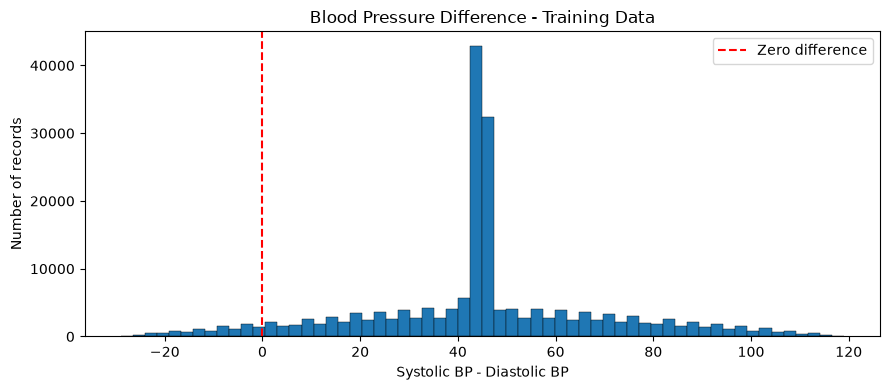

In [7]:
# STEP 7: Investigate Blood Pressure Inconsistencies
# Use training data only.

import pandas as pd
import matplotlib.pyplot as plt

bp_difference = (
    X_train["systolic_bp"] -
    X_train["diastolic_bp"]
)

equal_bp = (bp_difference == 0).sum()
reversed_bp = (bp_difference < 0).sum()
normal_order = (bp_difference > 0).sum()

print("=== BLOOD PRESSURE INVESTIGATION ===")
print("Systolic > Diastolic:", normal_order)
print("Systolic = Diastolic:", equal_bp)
print("Systolic < Diastolic:", reversed_bp)

print("\n=== PRESSURE DIFFERENCE SUMMARY ===")
print(bp_difference.describe().round(2))

print("\n=== NEGATIVE DIFFERENCES ===")
print(bp_difference[bp_difference < 0].describe().round(2))

# Visualize the distribution
plt.figure(figsize=(9, 4))

plt.hist(
    bp_difference,
    bins=60,
    edgecolor="black",
    linewidth=0.3
)

plt.axvline(
    0,
    color="red",
    linestyle="--",
    label="Zero difference"
)

plt.xlabel("Systolic BP - Diastolic BP")
plt.ylabel("Number of records")
plt.title("Blood Pressure Difference - Training Data")
plt.legend()
plt.tight_layout()
plt.show()

In [8]:
# STEP 8: Generate Experimental Engineered Features

import numpy as np
from src.feature_engineering import ClinicalFeatureEngineer

feature_engineer = ClinicalFeatureEngineer()

# Fit the transformer using training data only
X_train_engineered = feature_engineer.fit_transform(X_train)

# Apply the same feature calculations
X_val_engineered = feature_engineer.transform(X_val)
X_test_engineered = feature_engineer.transform(X_test)

engineered_columns = [
    "cholesterol_hdl_ratio",
    "triglycerides_hdl_ratio",
    "non_hdl_cholesterol",
    "age_bmi_interaction"
]

print("=== FEATURE ENGINEERING RESULTS ===")
print("Original predictor count:", X_train.shape[1])
print("Engineered predictor count:", X_train_engineered.shape[1])

print("\n=== NEW FEATURE SUMMARY ===")
display(
    X_train_engineered[engineered_columns]
    .describe()
    .round(2)
)

for name, dataset in [
    ("Training", X_train_engineered),
    ("Validation", X_val_engineered),
    ("Testing", X_test_engineered)
]:
    assert np.isfinite(
        dataset[engineered_columns].to_numpy(dtype=float)
    ).all()

    print(
        f"{name}: {len(dataset)} rows, "
        f"{dataset.shape[1]} predictors, "
        "all engineered values finite."
    )

=== FEATURE ENGINEERING RESULTS ===
Original predictor count: 24
Engineered predictor count: 28

=== NEW FEATURE SUMMARY ===


,cholesterol_hdl_ratio,triglycerides_hdl_ratio,non_hdl_cholesterol,age_bmi_interaction
count,195091.00,195091.00,195091.00,195091.00
mean,3.73,2.94,159.40,1381.10
std,1.31,1.30,39.14,710.44
min,1.52,0.51,51.00,23.12
25%,3.02,1.98,137.00,832.60
50%,3.48,2.77,160.36,1313.00
75%,3.98,3.87,179.00,1855.70
max,9.97,8.30,269.00,4600.80


Training: 195091 rows, 28 predictors, all engineered values finite.
Validation: 41806 rows, 28 predictors, all engineered values finite.
Testing: 41804 rows, 28 predictors, all engineered values finite.


In [9]:
# STEP 9: Integrated Feature Engineering + Preprocessing

import numpy as np

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import RobustScaler, OneHotEncoder

from src.feature_engineering import ClinicalFeatureEngineer

# Identify numeric and categorical columns after engineering
engineered_numeric_columns = (
    X_train_engineered.select_dtypes(include="number")
    .columns.tolist()
)

engineered_categorical_columns = (
    X_train_engineered.select_dtypes(
        include=["object", "category", "str"]
    ).columns.tolist()
)

# Numerical preprocessing
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", RobustScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

# Combine transformations
column_transformer = ColumnTransformer([
    ("numeric", numeric_transformer, engineered_numeric_columns),
    ("categorical", categorical_transformer, engineered_categorical_columns)
])

# One reusable pipeline
complete_pipeline = Pipeline([
    ("feature_engineering", ClinicalFeatureEngineer()),
    ("preprocessing", column_transformer)
])

# Fit only on training data
X_train_final = complete_pipeline.fit_transform(X_train)

# Transform validation and testing data
X_val_final = complete_pipeline.transform(X_val)
X_test_final = complete_pipeline.transform(X_test)

print("=== INTEGRATED PIPELINE RESULTS ===")
print("Training:", X_train_final.shape)
print("Validation:", X_val_final.shape)
print("Testing:", X_test_final.shape)

for name, data in [
    ("Training", X_train_final),
    ("Validation", X_val_final),
    ("Testing", X_test_final)
]:
    assert np.isfinite(data).all()
    print(f"{name}: All values are finite.")

print("\nSUCCESS: Integrated pipeline works correctly.")

=== INTEGRATED PIPELINE RESULTS ===
Training: (195091, 42)
Validation: (41806, 42)
Testing: (41804, 42)
Training: All values are finite.
Validation: All values are finite.
Testing: All values are finite.

SUCCESS: Integrated pipeline works correctly.


In [10]:
# STEP 10: Create the Final Feature Catalogue

import pandas as pd

# Retrieve transformed feature names
feature_names = (
    complete_pipeline
    .named_steps["preprocessing"]
    .get_feature_names_out()
)

assert len(feature_names) == X_train_final.shape[1]

feature_catalogue = pd.DataFrame({
    "Feature_Number": range(1, len(feature_names) + 1),
    "Transformed_Feature_Name": feature_names
})

print("=== FINAL FEATURE CATALOGUE ===")
print("Total transformed features:", len(feature_catalogue))

display(feature_catalogue)

# Save to project results
output_path = (
    project_root
    / "results"
    / "tables"
    / "part2_transformed_feature_catalogue.csv"
)

output_path.parent.mkdir(parents=True, exist_ok=True)

feature_catalogue.to_csv(output_path, index=False)

print("\nSaved:", output_path)

=== FINAL FEATURE CATALOGUE ===
Total transformed features: 42


,Feature_Number,Transformed_Feature_Name
0,1,numeric__age
1,2,numeric__bmi
2,3,numeric__HbA1c_level
3,4,numeric__glucose
4,5,numeric__cholesterol
5,6,numeric__sleep_hours
6,7,numeric__triglycerides
7,8,numeric__crp_level
8,9,numeric__homocysteine_level
9,10,numeric__systolic_bp



Saved: D:\chronic-disease-ml\results\tables\part2_transformed_feature_catalogue.csv


In [11]:
# STEP 11: Document Engineered Features

import pandas as pd

engineering_catalogue = pd.DataFrame([
    {
        "Feature": "cholesterol_hdl_ratio",
        "Input_Columns": "cholesterol, hdl",
        "Formula": "cholesterol / hdl",
        "Rationale": "Represent the relative relationship between total cholesterol and HDL.",
        "Interpretation": "Higher values indicate more total cholesterol relative to HDL.",
        "Limitations": "Requires compatible cholesterol and HDL units; not clinically validated in this dataset."
    },
    {
        "Feature": "triglycerides_hdl_ratio",
        "Input_Columns": "triglycerides, hdl",
        "Formula": "triglycerides / hdl",
        "Rationale": "Represent the relationship between triglycerides and HDL.",
        "Interpretation": "Higher values indicate more triglycerides relative to HDL.",
        "Limitations": "Requires verified units; clinical meaning depends on measurement context."
    },
    {
        "Feature": "non_hdl_cholesterol",
        "Input_Columns": "cholesterol, hdl",
        "Formula": "cholesterol - hdl",
        "Rationale": "Represent cholesterol excluding the HDL component.",
        "Interpretation": "Difference between total cholesterol and HDL.",
        "Limitations": "Requires consistent units and verified measurement definitions."
    },
    {
        "Feature": "age_bmi_interaction",
        "Input_Columns": "age, bmi",
        "Formula": "age * bmi",
        "Rationale": "Capture a possible interaction between age and BMI.",
        "Interpretation": "Larger values reflect higher combined age and BMI.",
        "Limitations": "Experimental interaction; not an established clinical risk score."
    }
])

display(engineering_catalogue)

output_file = (
    project_root
    / "results"
    / "tables"
    / "part2_engineered_feature_catalogue.csv"
)

output_file.parent.mkdir(parents=True, exist_ok=True)

engineering_catalogue.to_csv(
    output_file,
    index=False
)

print("\nSaved:", output_file)
print("Engineered features documented:", len(engineering_catalogue))

,Feature,Input_Columns,Formula,Rationale,Interpretation,Limitations
0,cholesterol_hdl_ratio,"cholesterol, hdl",cholesterol / hdl,Represent the relative relationship between to...,Higher values indicate more total cholesterol ...,Requires compatible cholesterol and HDL units;...
1,triglycerides_hdl_ratio,"triglycerides, hdl",triglycerides / hdl,Represent the relationship between triglycerid...,Higher values indicate more triglycerides rela...,Requires verified units; clinical meaning depe...
2,non_hdl_cholesterol,"cholesterol, hdl",cholesterol - hdl,Represent cholesterol excluding the HDL compon...,Difference between total cholesterol and HDL.,Requires consistent units and verified measure...
3,age_bmi_interaction,"age, bmi",age * bmi,Capture a possible interaction between age and...,Larger values reflect higher combined age and ...,Experimental interaction; not an established c...



Saved: D:\chronic-disease-ml\results\tables\part2_engineered_feature_catalogue.csv
Engineered features documented: 4


In [12]:
# STEP 12: Verify the Reusable Preprocessing Module

import numpy as np
import importlib
import src.pipeline as pipeline_module

importlib.reload(pipeline_module)

build_pipeline = pipeline_module.build_pipeline

# Create original-feature and engineered-feature pipelines
baseline_pipeline = build_pipeline(
    X_train,
    use_engineering=False
)

engineered_pipeline = build_pipeline(
    X_train,
    use_engineering=True
)

# Fit using training data only
X_train_baseline = baseline_pipeline.fit_transform(X_train)
X_train_engineered_final = engineered_pipeline.fit_transform(X_train)

print("=== REUSABLE PIPELINE VERIFICATION ===")
print("Baseline:", X_train_baseline.shape)
print("Engineered:", X_train_engineered_final.shape)

# Compare reusable output with notebook output
assert X_train_baseline.shape[1] == 38
assert X_train_engineered_final.shape[1] == 42

assert np.allclose(
    X_train_engineered_final,
    X_train_final
)

assert np.isfinite(X_train_baseline).all()
assert np.isfinite(X_train_engineered_final).all()

print("\nSUCCESS: Reusable pipeline matches notebook results.")

=== REUSABLE PIPELINE VERIFICATION ===
Baseline: (195091, 38)
Engineered: (195091, 42)

SUCCESS: Reusable pipeline matches notebook results.


In [13]:
# STEP 13: Compare Original vs Engineered Features
# Preliminary experiment using training and validation data only.

import time
import pandas as pd

from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    balanced_accuracy_score
)

from src.pipeline import build_pipeline

# Use a reproducible, stratified training sample
# to keep this initial experiment manageable.
sample_indices, _ = train_test_split(
    X_train.index,
    train_size=50000,
    stratify=y_train,
    random_state=42
)

X_sample = X_train.loc[sample_indices]
y_sample = y_train.loc[sample_indices]

results = []

experiments = [
    ("Original Features", False),
    ("Engineered Features", True)
]

for name, use_engineering in experiments:
    print(f"\nTraining: {name}")

    model_pipeline = Pipeline([
        ("preprocessor", build_pipeline(
            X_sample,
            use_engineering=use_engineering
        )),
        ("classifier", LogisticRegression(
            max_iter=500,
            class_weight="balanced",
            solver="lbfgs"
        ))
    ])

    start = time.perf_counter()

    # Fit preprocessing and classifier on training sample
    model_pipeline.fit(X_sample, y_sample)

    # Evaluate only on validation data
    predictions = model_pipeline.predict(X_val)

    elapsed = time.perf_counter() - start

    results.append({
        "Feature_Set": name,
        "Accuracy": accuracy_score(y_val, predictions),
        "Macro_F1": f1_score(
            y_val, predictions, average="macro"
        ),
        "Weighted_F1": f1_score(
            y_val, predictions, average="weighted"
        ),
        "Balanced_Accuracy": balanced_accuracy_score(
            y_val, predictions
        ),
        "Runtime_Seconds": elapsed
    })

comparison_df = pd.DataFrame(results)

print("\n=== FEATURE COMPARISON RESULTS ===")
display(comparison_df.round(4))

print("\nMacro F1 difference (Engineered - Original):")
difference = (
    comparison_df.loc[1, "Macro_F1"]
    - comparison_df.loc[0, "Macro_F1"]
)
print(round(difference, 4))

print("\nNOTE: Final test set was not used.")


Training: Original Features

Training: Engineered Features

=== FEATURE COMPARISON RESULTS ===


,Feature_Set,Accuracy,Macro_F1,Weighted_F1,Balanced_Accuracy,Runtime_Seconds
0,Original Features,0.4674,0.2731,0.5347,0.4156,2.4867
1,Engineered Features,0.4906,0.2940,0.5571,0.4578,8.1743



Macro F1 difference (Engineered - Original):
0.0209

NOTE: Final test set was not used.


In [14]:
# STEP 14: Full Training Set Feature Comparison
# Training: 195,091 records
# Validation: 41,806 records
# Test set is NOT used.

import time
import pandas as pd

from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    balanced_accuracy_score
)

from src.pipeline import build_pipeline

full_results = []

for name, use_engineering in [
    ("Original Features", False),
    ("Engineered Features", True)
]:
    print(f"\nTraining model: {name}")

    model = Pipeline([
        ("preprocessor", build_pipeline(
            X_train,
            use_engineering=use_engineering
        )),
        ("classifier", LogisticRegression(
            max_iter=1000,
            class_weight="balanced",
            solver="lbfgs"
        ))
    ])

    start = time.perf_counter()

    model.fit(X_train, y_train)

    predictions = model.predict(X_val)

    elapsed = time.perf_counter() - start

    full_results.append({
        "Feature_Set": name,
        "Accuracy": accuracy_score(y_val, predictions),
        "Macro_F1": f1_score(
            y_val, predictions, average="macro"
        ),
        "Weighted_F1": f1_score(
            y_val, predictions, average="weighted"
        ),
        "Balanced_Accuracy": balanced_accuracy_score(
            y_val, predictions
        ),
        "Runtime_Seconds": elapsed
    })

    print(f"Completed: {name}")

full_comparison_df = pd.DataFrame(full_results)

print("\n=== FULL TRAINING COMPARISON ===")
display(full_comparison_df.round(4))

macro_difference = (
    full_comparison_df.loc[1, "Macro_F1"]
    - full_comparison_df.loc[0, "Macro_F1"]
)

print("\nMacro F1 difference:", round(macro_difference, 4))
print("Final test set remains unused.")


Training model: Original Features
Completed: Original Features

Training model: Engineered Features
Completed: Engineered Features

=== FULL TRAINING COMPARISON ===


,Feature_Set,Accuracy,Macro_F1,Weighted_F1,Balanced_Accuracy,Runtime_Seconds
0,Original Features,0.4634,0.2739,0.5314,0.4271,6.7926
1,Engineered Features,0.4894,0.2961,0.5552,0.4739,38.6486



Macro F1 difference: 0.0222
Final test set remains unused.


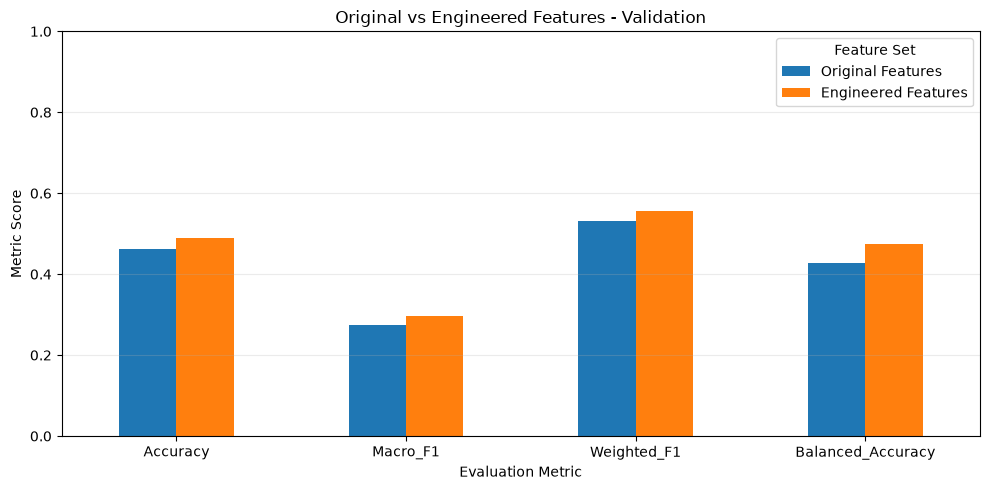

Results saved:
D:\chronic-disease-ml\results\tables\part2_full_feature_comparison.csv
D:\chronic-disease-ml\results\figures\part2_feature_comparison.png


In [15]:
# STEP 15: Save Feature Comparison Results

import matplotlib.pyplot as plt
from pathlib import Path

tables_dir = project_root / "results" / "tables"
figures_dir = project_root / "results" / "figures"

tables_dir.mkdir(parents=True, exist_ok=True)
figures_dir.mkdir(parents=True, exist_ok=True)

# Save the comparison table
table_path = (
    tables_dir / "part2_full_feature_comparison.csv"
)

full_comparison_df.to_csv(table_path, index=False)

# Create comparison graph
metrics = [
    "Accuracy",
    "Macro_F1",
    "Weighted_F1",
    "Balanced_Accuracy"
]

plot_data = full_comparison_df.set_index("Feature_Set")[metrics].T

ax = plot_data.plot(
    kind="bar",
    figsize=(10, 5),
    rot=0
)

ax.set_title("Original vs Engineered Features - Validation")
ax.set_ylabel("Metric Score")
ax.set_xlabel("Evaluation Metric")
ax.set_ylim(0, 1)
ax.legend(title="Feature Set")
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()

figure_path = (
    figures_dir / "part2_feature_comparison.png"
)

plt.savefig(figure_path, dpi=200, bbox_inches="tight")
plt.show()

print("Results saved:")
print(table_path)
print(figure_path)

In [16]:
# STEP 16: Final Pipeline Validation

import numpy as np
import pandas as pd

from src.pipeline import build_pipeline

# Construct a fresh reusable transformer
verified_pipeline = build_pipeline(
    X_train,
    use_engineering=True
)

# Fit using training data only
train_verified = verified_pipeline.fit_transform(X_train)

# Transform validation data
validation_verified = verified_pipeline.transform(X_val)

# Confirm dimensions and finite values
assert train_verified.shape == (195091, 42)
assert validation_verified.shape == (41806, 42)

assert np.isfinite(train_verified).all()
assert np.isfinite(validation_verified).all()

# Check the fitted output feature names
verified_names = (
    verified_pipeline.named_steps["preprocessing"]
    .get_feature_names_out()
)

assert len(verified_names) == 42
assert len(set(verified_names)) == 42

# Confirm consistent outputs with the notebook
assert np.allclose(train_verified, X_train_final)
assert np.allclose(validation_verified, X_val_final)

print("=== FINAL REPRODUCIBILITY CHECK ===")
print("Training shape:", train_verified.shape)
print("Validation shape:", validation_verified.shape)
print("Feature names:", len(verified_names))
print("Invalid values:", np.size(train_verified) - np.isfinite(train_verified).sum())

print("\nSUCCESS: Reusable preprocessing verified.")

=== FINAL REPRODUCIBILITY CHECK ===
Training shape: (195091, 42)
Validation shape: (41806, 42)
Feature names: 42
Invalid values: 0

SUCCESS: Reusable preprocessing verified.
